# Korrelationsanalyse nach Region

Durchschnittliche Zufriedenheit und Freiheit pro Subregion und Jahr sowie deren Korrelation.

In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 250)

In [8]:
from bina_db import connect

maria_db_connection = connect()

In [9]:
sql_query = "with avg_happy as (select c.subregion as region, year, truncate(avg(value), 3) as avg from metric join country c on c.id = metric.country where metric_definition = 2 and country in (1, 3, 4, 7, 11, 12, 14, 15, 16, 18, 19, 21, 22, 24, 26, 27, 29, 30, 32, 35, 36, 37, 39, 40, 41, 43, 44, 45, 46, 49, 50, 51, 54, 56, 59, 60, 61, 62, 64, 65, 66, 67, 70, 72, 76, 77, 81, 83, 84, 85, 87, 92, 94, 97, 100, 101, 102, 103, 104, 105, 106, 107, 108, 110, 111, 112, 113, 115, 116, 117, 120, 121, 122, 123, 124, 125, 126, 127, 128, 130, 131, 133, 134, 135, 137, 138, 141, 142, 144, 146, 148, 149, 151, 152, 153, 156, 157, 159, 160, 161, 162, 165, 167, 168, 169, 171, 172, 174, 175, 176, 178, 179, 181, 183, 184, 185, 196, 197, 198, 200, 201, 203, 204, 206, 207, 210, 211, 212, 213, 215, 216, 217, 218, 219, 220, 221, 223, 226, 227, 228, 229, 232, 233, 234, 235, 236, 238, 239, 241, 242, 247, 248, 249, 250) group by c.subregion, year), avg_freedom as (select c.subregion as region, year, truncate(avg(value), 3) as avg from metric join country c on c.id = metric.country where metric_definition = 7 and country in (1, 3, 4, 7, 11, 12, 14, 15, 16, 18, 19, 21, 22, 24, 26, 27, 29, 30, 32, 35, 36, 37, 39, 40, 41, 43, 44, 45, 46, 49, 50, 51, 54, 56, 59, 60, 61, 62, 64, 65, 66, 67, 70, 72, 76, 77, 81, 83, 84, 85, 87, 92, 94, 97, 100, 101, 102, 103, 104, 105, 106, 107, 108, 110, 111, 112, 113, 115, 116, 117, 120, 121, 122, 123, 124, 125, 126, 127, 128, 130, 131, 133, 134, 135, 137, 138, 141, 142, 144, 146, 148, 149, 151, 152, 153, 156, 157, 159, 160, 161, 162, 165, 167, 168, 169, 171, 172, 174, 175, 176, 178, 179, 181, 183, 184, 185, 196, 197, 198, 200, 201, 203, 204, 206, 207, 210, 211, 212, 213, 215, 216, 217, 218, 219, 220, 221, 223, 226, 227, 228, 229, 232, 233, 234, 235, 236, 238, 239, 241, 242, 247, 248, 249, 250) group by c.subregion, year) select ah.region as continent, ah.year as year, ah.avg as happiness, af.avg as freedom from avg_happy as ah join avg_freedom as af on ah.region = af.region and ah.year = af.year"

sql_data = pd.read_sql(sql_query, maria_db_connection)

In [10]:
sql_data

,continent,year,happiness,freedom
0,Australia and New Zealand,2015,7.284,0.645
1,Australia and New Zealand,2016,7.323,0.574
2,Australia and New Zealand,2017,7.299,0.607
3,Australia and New Zealand,2018,7.297,0.658
4,Australia and New Zealand,2019,7.267,0.570
5,Central Asia,2015,5.495,0.511
6,Central Asia,2016,5.548,0.444
7,Central Asia,2017,5.531,0.488
8,Central Asia,2018,5.570,0.485
9,Central Asia,2019,5.591,0.466


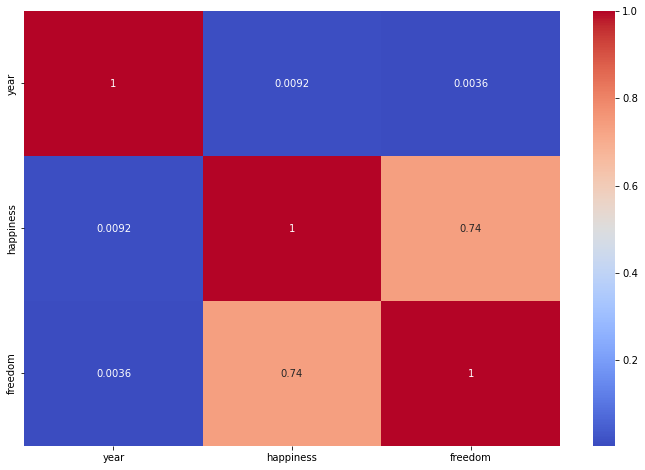

In [18]:
sql_data[["happiness", "freedom"]].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(sql_data.corr(), annot=True, cmap='coolwarm')
plt.show()